In [1]:
import cv2
from cv2.typing import MatLike
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
data_folder = Path("../data/dart_boards")

def load_boards(folder: Path) -> dict[str, np.ndarray]:
    boards = {}

    for path in folder.iterdir():
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            image = cv2.imread(str(path))

            if image is not None:
                boards[path.stem] = image

    return boards

boards = load_boards(data_folder)


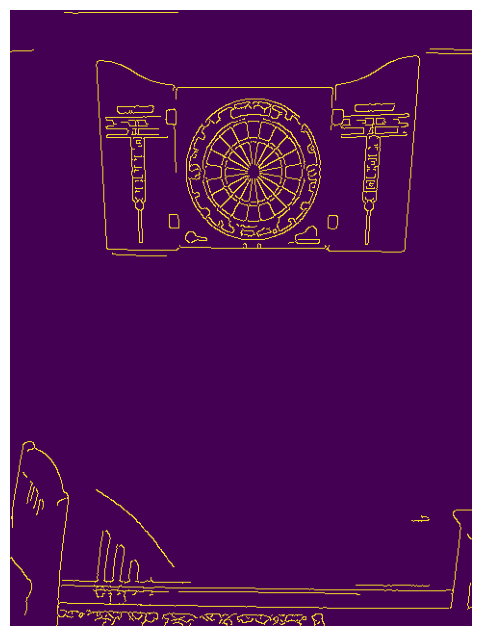

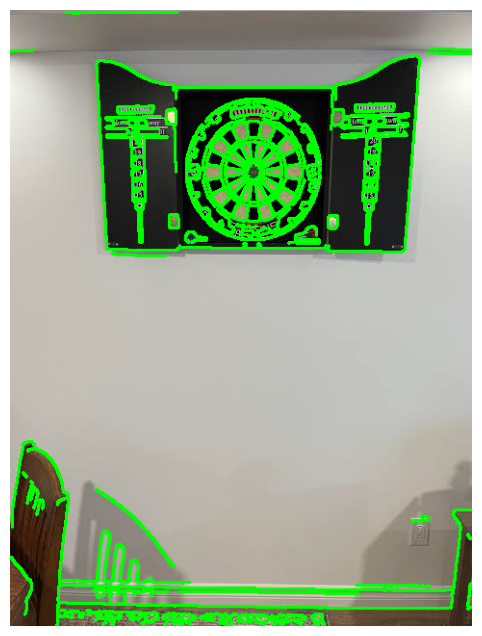

Number of contours: 199


In [3]:
import cv2
import numpy as np


frame_org = boards["board 7"]

# Convert to gray scale
frame = cv2.cvtColor(frame_org, cv2.COLOR_RGB2GRAY)
# frame = frame[:,:, ]

# # Create a CLAHE object with a clip limit of 2.0 and a tile grid size of 8x8
clahe = cv2.createCLAHE(clipLimit=2, tileGridSize=(12,12))
frame = clahe.apply(frame)

# # Perform Gaussian filtering to reduce noise and improve edge detection
frame = cv2.GaussianBlur(frame, (7, 7), 0)

# # Perform Canny edge detection
frame = cv2.Canny(frame, 100, 150)
# frame = cv2.GaussianBlur(frame, (3, 3), 0)
# frame = cv2.Canny(frame, 100, 250)

plt.figure(figsize=(10, 8))
plt.imshow(frame)
plt.axis("off")
plt.show()

# Find contours from the Canny edge image
contours, hierarchy = cv2.findContours(
    frame,
    cv2.RETR_LIST,
    cv2.CHAIN_APPROX_SIMPLE
)

# Copy original image to visualize contours
contour_image = frame_org.copy()

# Draw all detected contours
cv2.drawContours(contour_image, contours, -1, (0, 255, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(contour_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

print("Number of contours:", len(contours))



In [4]:
contours, hierarchy = cv2.findContours(
    frame,
    cv2.RETR_LIST,
    cv2.CHAIN_APPROX_NONE
)

height, width = frame.shape
candidates = []

# Allow a small tolerance when comparing ellipses with edges
expanded_edges = cv2.dilate(frame, np.ones((3, 3), np.uint8))

for contour in contours:

    if len(contour) < 30:
        continue

    ellipse = cv2.fitEllipse(contour)

    (cx, cy), (a, b), angle = ellipse

    if min(a, b) <= 0:
        continue

    # 1. Check ellipse shape
    ratio = min(a, b) / max(a, b)

    if ratio < 0.45:
        continue

    # 2. Check ellipse size
    area = np.pi * a * b / 4

    if area < 0.02 * height * width:
        continue

    if max(a, b) > 1.5 * max(height, width):
        continue

    # 3. Check whether detected edges follow the ellipse
    ellipse_mask = np.zeros_like(frame)
    cv2.ellipse(ellipse_mask, ellipse, 255, 2)

    ys, xs = np.where(ellipse_mask > 0)
    matching = expanded_edges[ys, xs] > 0

    support = np.mean(matching)

    # 4. Check whether edges cover the ellipse
    # rather than just a small arc
    angles = np.arctan2(ys[matching] - cy, xs[matching] - cx)
    bins = np.floor((angles + np.pi) / (2 * np.pi) * 36)
    coverage = len(np.unique(np.clip(bins, 0, 35))) / 36

    # Prefer large ellipses with good edge support
    score = support * coverage * np.sqrt(area)

    candidates.append((score, ellipse))

# Sort by score
candidates.sort(key=lambda x: x[0], reverse=True)

In [5]:
def local_contrast(frame, lim = 1.0, grid = (8,8)):
    clahe = cv2.createCLAHE(clipLimit = lim, tileGridSize = grid)
    return clahe.apply(frame)

def find_ellipse_candidates(frame, contours):
    height, width = frame.shape
    candidates = []

    # Allow tolerance when comparing ellipses with edges
    expanded_edges = cv2.dilate(
        frame, np.ones((3, 3), np.uint8)
    )

    for contour in contours:

        if len(contour) < 30:
            continue

        ellipse = cv2.fitEllipse(contour)
        (cx, cy), (a, b), angle = ellipse

        if min(a, b) <= 0:
            continue

        # 1. Check ellipse shape
        ratio = min(a, b) / max(a, b)

        if ratio < 0.45:
            continue

        # 2. Check ellipse size
        area = np.pi * a * b / 4

        if area < 0.02 * height * width:
            continue

        if max(a, b) > 1.5 * max(height, width):
            continue

        # 3. Check whether edges follow the ellipse
        ellipse_mask = np.zeros_like(frame)
        cv2.ellipse(ellipse_mask, ellipse, 255, 2)

        ys, xs = np.where(ellipse_mask > 0)

        if len(xs) == 0:
            continue

        matching = expanded_edges[ys, xs] > 0
        support = np.mean(matching)

        # 4. Check angular coverage
        angles = np.arctan2(
            ys[matching] - cy,
            xs[matching] - cx
        )

        bins = np.floor(
            (angles + np.pi) / (2 * np.pi) * 36
        )

        coverage = len(
            np.unique(np.clip(bins, 0, 35))
        ) / 36

        # 5. Calculate score
        score = support * coverage * np.sqrt(area)

        candidates.append((score, ellipse))

    # Sort by score (highest first)
    candidates.sort(key=lambda x: x[0], reverse=True)

    return candidates

In [6]:
def draw_perspective_regions(output, H, center, r_double):

    cx, cy = center

    # Scoring ring radii in millimeters
    rings = [6.35, 15.9, 99.4, 107.4, 162, 170]

    # Draw projected scoring rings
    for r in rings:

        radius_px = r_double * r / 170

        angles = np.linspace(0, 2 * np.pi, 360)

        points = np.column_stack((
            cx + radius_px * np.sin(angles),
            cy - radius_px * np.cos(angles)
        )).astype(np.float32)

        points = points.reshape(-1, 1, 2)

        # Apply perspective transformation
        projected = cv2.perspectiveTransform(points, H)

        if not np.isfinite(projected).all():
            continue

        projected = np.round(projected).astype(np.int32)

        cv2.polylines(
            output,
            [projected],
            True,
            (0, 255, 0),
            1,
            cv2.LINE_AA
        )

    # Draw 20 radial sector boundaries
    for i in range(20):

        theta = np.radians(i * 18 - 9)

        direction = np.array([
            np.sin(theta),
            -np.cos(theta)
        ])

        inner = np.array([cx, cy]) + (
            r_double * 15.9 / 170
        ) * direction

        outer = np.array([cx, cy]) + r_double * direction

        points = np.float32([inner, outer]).reshape(-1, 1, 2)

        projected = cv2.perspectiveTransform(points, H)

        if not np.isfinite(projected).all():
            continue

        p1, p2 = np.round(
            projected.reshape(2, 2)
        ).astype(int)

        cv2.line(
            output,
            tuple(p1),
            tuple(p2),
            (0, 255, 0),
            1,
            cv2.LINE_AA
        )

    return output

In [ ]:

import cv2

print("Opening camera...")

cap = cv2.VideoCapture(1, cv2.CAP_DSHOW)

if not cap.isOpened():
    print("Camera could not be opened!")
    exit()

print("Camera opened successfully!")

while True:
    ret, frame = cap.read()
    img = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)


    #####################################################################################
    # Apply CLAHE to enhance local contrast and improve visibility of features
    frame_clahe = local_contrast(img, lim = 5)
    # Perform Gaussian filtering to reduce noise and improve edge detection
    frame_gaus = cv2.GaussianBlur(frame_clahe, (3, 3), 0)

    # Perform Canny edge detection
    edges = cv2.Canny(frame_gaus, 100, 150)

    # Find contours from the Canny edge image
    contours, hierarchy = cv2.findContours(
        edges,
        cv2.RETR_LIST,
        cv2.CHAIN_APPROX_SIMPLE
    )


    candidates = find_ellipse_candidates(edges, contours)

    output = frame.copy()

    # Draw the 1 highest-ranked ellipses
    for score, ellipse in candidates[:1]:
        cv2.ellipse(output, ellipse, (0, 255, 0), 2)
        

    if not ret:
        print("Failed to read frame")
        break

    cv2.imshow("Original", frame)
    cv2.imshow("Camera", output)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()


Opening camera...
Camera opened successfully!
